<a href="https://colab.research.google.com/github/KarunyaVarma/Karunya-Varma/blob/main/Tabular_Res_net_5fold_Cross_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting 5-Fold Cross-Validation for Tabular ResNet...

Fold 1 (Best Epoch  44) -> MAE: 0.6897 | RMSE: 0.9762 | R2: 0.976029
Fold 2 (Best Epoch  85) -> MAE: 0.6379 | RMSE: 0.9247 | R2: 0.978862
Fold 3 (Best Epoch  74) -> MAE: 0.6550 | RMSE: 0.9570 | R2: 0.973739
Fold 4 (Best Epoch  79) -> MAE: 0.6373 | RMSE: 0.9529 | R2: 0.977732
Fold 5 (Best Epoch  43) -> MAE: 0.7017 | RMSE: 1.2685 | R2: 0.955066

          5-FOLD CROSS-VALIDATION SUMMARY (TABULAR RESNET)
 Fold  Best Epoch      MAE     RMSE       R2
    1          44 0.689731 0.976201 0.976029
    2          85 0.637936 0.924675 0.978862
    3          74 0.654960 0.957021 0.973739
    4          79 0.637345 0.952870 0.977732
    5          43 0.701727 1.268462 0.955066
------------------------------------------------------------------------
Mean MAE      : 0.664340 +/- 0.029818 MW
Mean RMSE     : 1.015846 +/- 0.142413 MW
Mean R2 Score : 0.972286 +/- 0.009818

       FINAL UNTOUCHED 20% HOLDOUT TEST EVALUATION (TABULAR RESNET)
Holdout

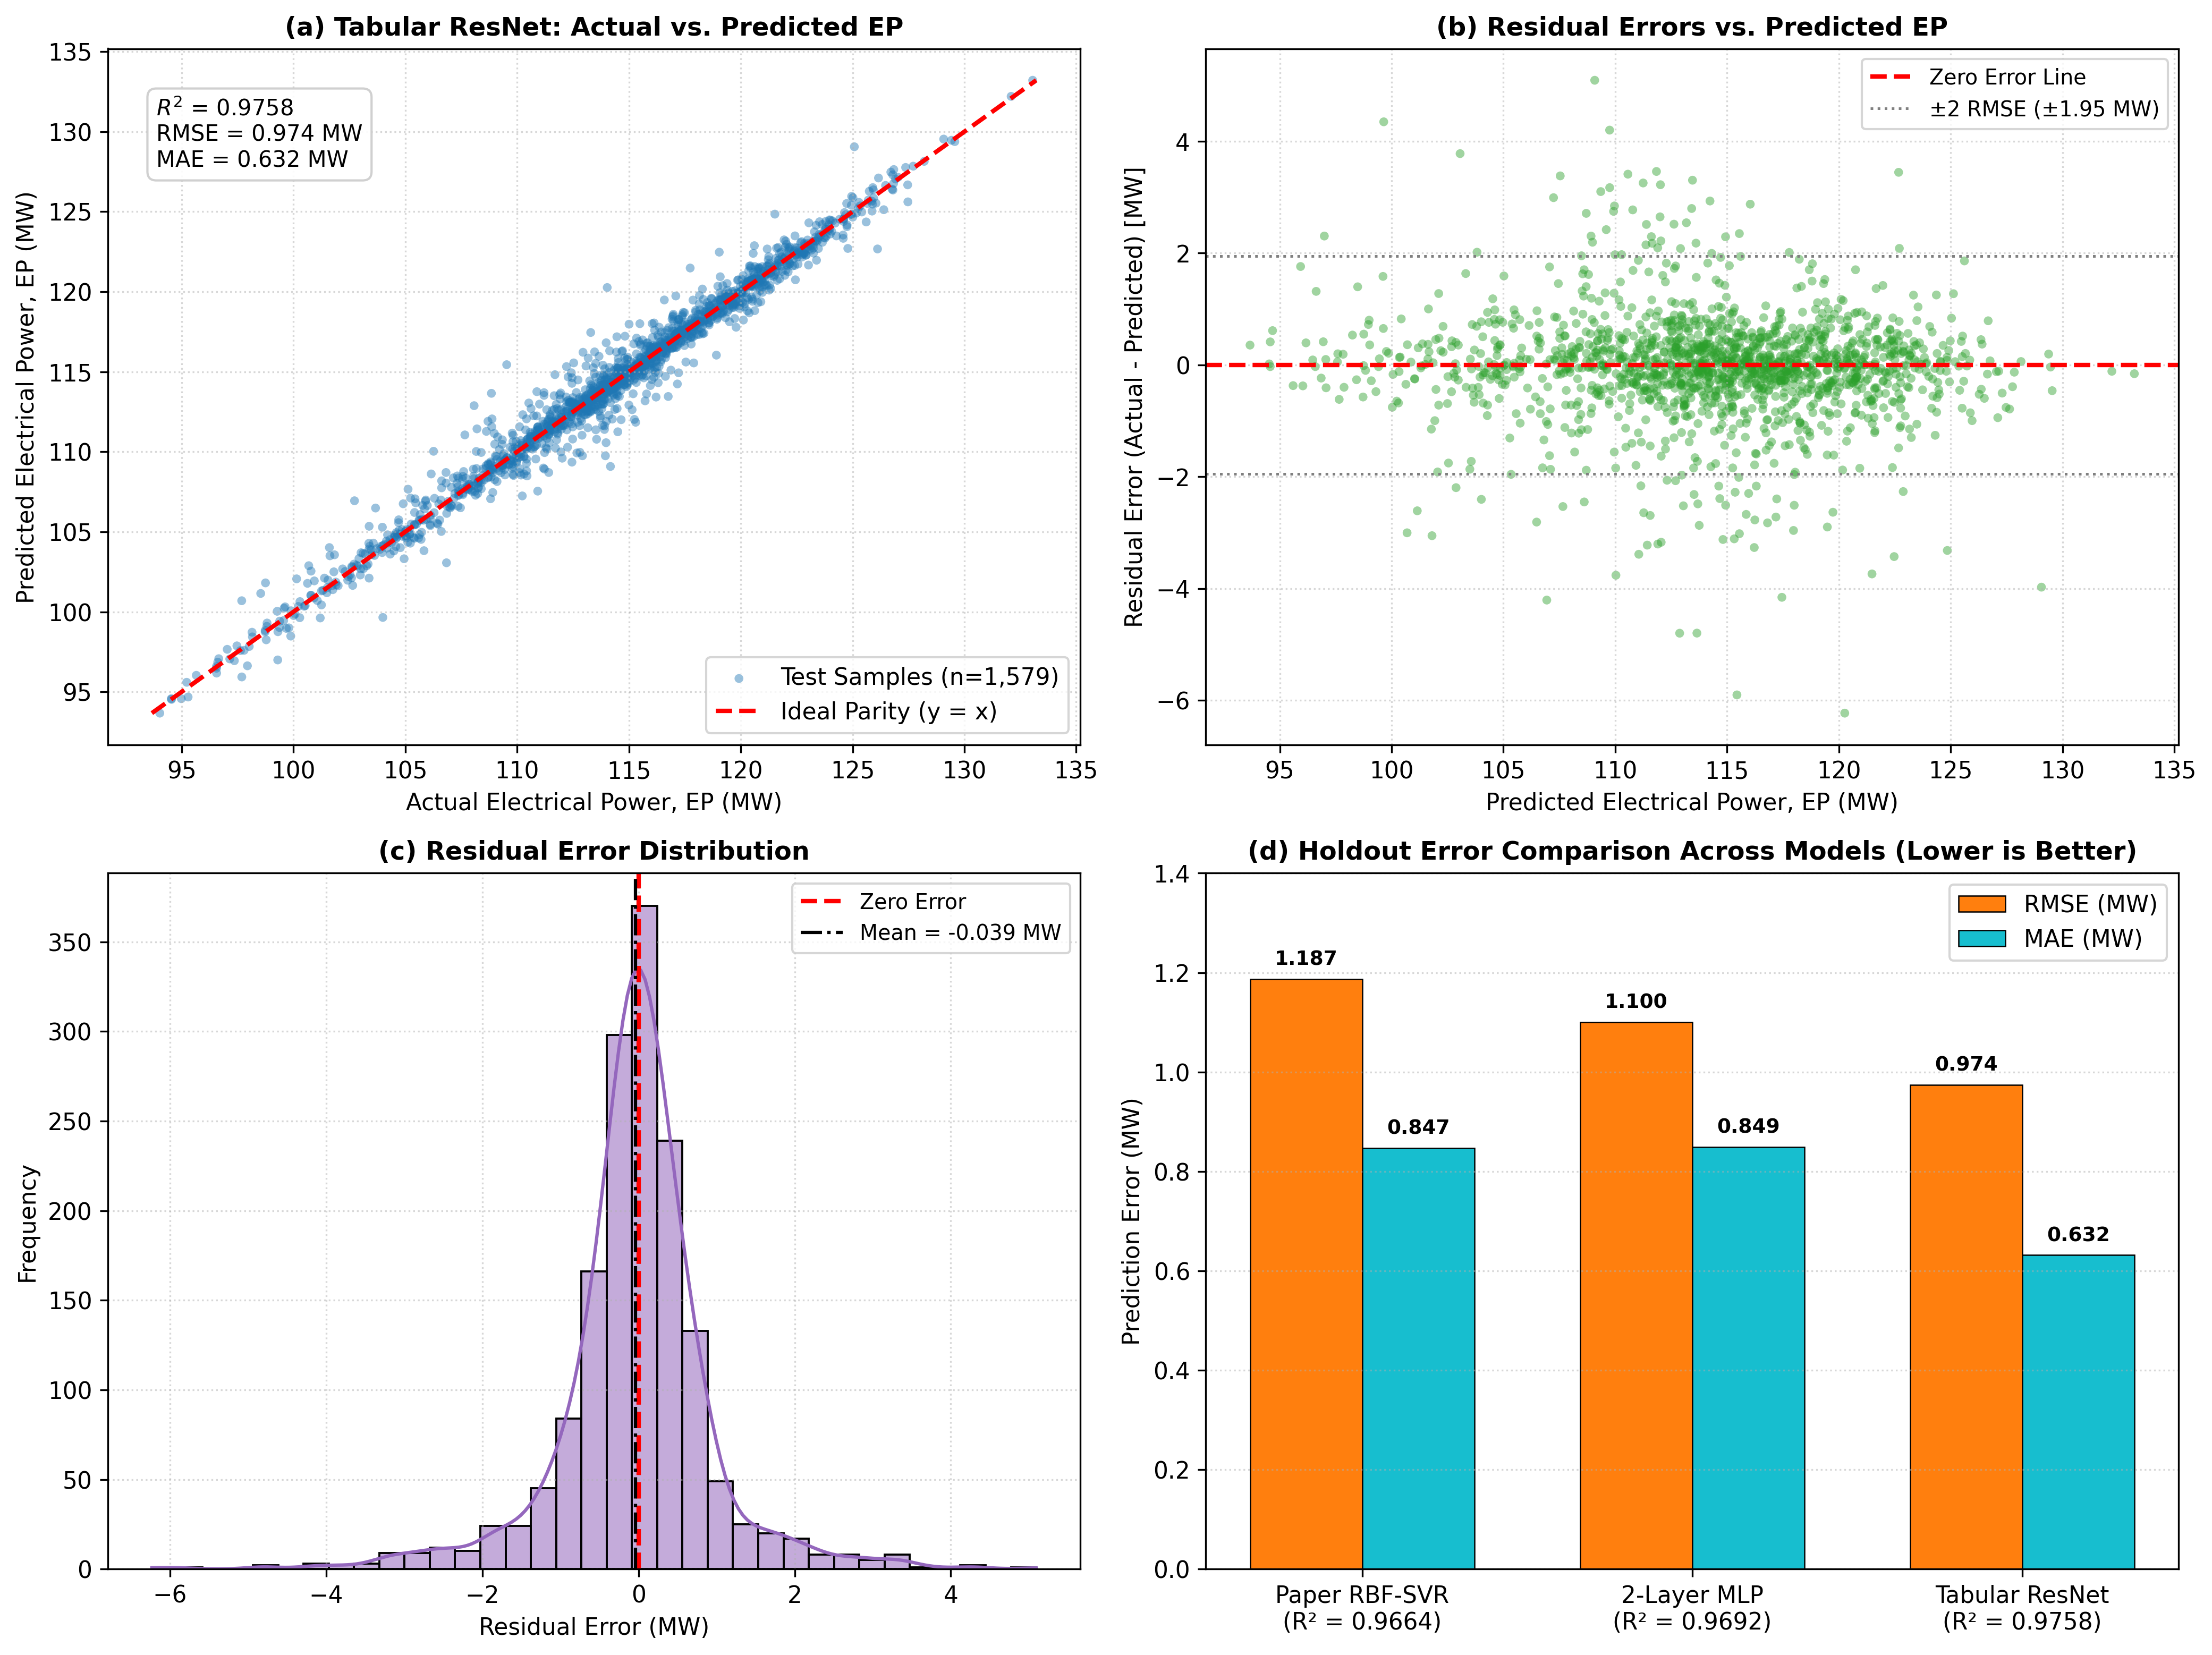

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import RobustScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -------------------------------------------------
# 1. Reproducibility & Data Loading
# -------------------------------------------------
tf.keras.utils.set_random_seed(42)

data = pd.read_csv('/content/GTPP-DATASET.csv')
X = data[['AT', 'AP', 'DF', 'CH', 'GP', 'CPR', 'CPD', 'TTXM']].values
y = data['EP'].values

# Locked 80:20 Holdout Split
X_train_full, X_test_holdout, y_train_full, y_test_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# -------------------------------------------------
# 2. Tabular ResNet Architecture Builder
# -------------------------------------------------
def build_tabular_resnet(input_dim, n_samples, epochs=200, batch_size=16):
    inputs = tf.keras.layers.Input(shape=(input_dim,))

    # Initial projection
    x = tf.keras.layers.Dense(128, activation='swish')(inputs)
    x = tf.keras.layers.LayerNormalization()(x)

    # Residual Block 1
    shortcut = x
    r = tf.keras.layers.Dense(128, activation='swish')(x)
    r = tf.keras.layers.Dropout(0.1)(r)
    r = tf.keras.layers.Dense(128)(r)
    x = tf.keras.layers.Add()([shortcut, r])
    x = tf.keras.layers.Activation('swish')(x)
    x = tf.keras.layers.LayerNormalization()(x)

    # Residual Block 2
    shortcut = x
    r = tf.keras.layers.Dense(128, activation='swish')(x)
    r = tf.keras.layers.Dropout(0.1)(r)
    r = tf.keras.layers.Dense(128)(r)
    x = tf.keras.layers.Add()([shortcut, r])
    x = tf.keras.layers.Activation('swish')(x)

    # Output head + direct linear skip from inputs
    linear_skip = tf.keras.layers.Dense(1)(inputs)
    nonlinear_out = tf.keras.layers.Dense(1)(x)
    outputs = tf.keras.layers.Add()([linear_skip, nonlinear_out])

    model = tf.keras.Model(inputs, outputs)

    lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.003,
        decay_steps=epochs * (n_samples // batch_size),
        alpha=1e-5
    )

    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4),
        loss='huber',
        metrics=['mae']
    )
    return model

# -------------------------------------------------
# 3. Sub-Step 4A: 5-Fold Cross-Validation (80% Train)
# -------------------------------------------------
EPOCHS = 200
BATCH_SIZE = 16
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
print("Starting 5-Fold Cross-Validation for Tabular ResNet...\n")

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_full), start=1):
    tf.keras.utils.set_random_seed(42 + fold)

    X_f_train_raw, X_f_val_raw = X_train_full[train_idx], X_train_full[val_idx]
    y_f_train, y_f_val = y_train_full[train_idx], y_train_full[val_idx]

    # Fit PolynomialFeatures & RobustScaler strictly inside each fold
    poly = PolynomialFeatures(degree=2, include_bias=False)
    X_f_train_poly = poly.fit_transform(X_f_train_raw)
    X_f_val_poly = poly.transform(X_f_val_raw)

    scaler = RobustScaler()
    X_f_train = scaler.fit_transform(X_f_train_poly)
    X_f_val = scaler.transform(X_f_val_poly)

    fold_model = build_tabular_resnet(
        input_dim=X_f_train.shape[1],
        n_samples=len(X_f_train),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=25,
        restore_best_weights=True,
        verbose=0
    )

    history = fold_model.fit(
        X_f_train, y_f_train,
        validation_data=(X_f_val, y_f_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=0
    )

    best_epoch = np.argmin(history.history['val_loss']) + 1
    y_val_pred = fold_model.predict(X_f_val, verbose=0).flatten()

    f_mae = mean_absolute_error(y_f_val, y_val_pred)
    f_rmse = np.sqrt(mean_squared_error(y_f_val, y_val_pred))
    f_r2 = r2_score(y_f_val, y_val_pred)

    cv_results.append((fold, best_epoch, f_mae, f_rmse, f_r2))
    print(f"Fold {fold} (Best Epoch {best_epoch:3d}) -> MAE: {f_mae:.4f} | RMSE: {f_rmse:.4f} | R2: {f_r2:.6f}")

cv_df = pd.DataFrame(cv_results, columns=['Fold', 'Best Epoch', 'MAE', 'RMSE', 'R2'])

print("\n" + "="*72)
print("          5-FOLD CROSS-VALIDATION SUMMARY (TABULAR RESNET)")
print("="*72)
print(cv_df.to_string(index=False))
print("-"*72)
print(f"Mean MAE      : {cv_df['MAE'].mean():.6f} +/- {cv_df['MAE'].std():.6f} MW")
print(f"Mean RMSE     : {cv_df['RMSE'].mean():.6f} +/- {cv_df['RMSE'].std():.6f} MW")
print(f"Mean R2 Score : {cv_df['R2'].mean():.6f} +/- {cv_df['R2'].std():.6f}")
print("="*72 + "\n")

# -------------------------------------------------
# 4. Sub-Step 4B: Final Refit on Full 80% & Holdout Test
# -------------------------------------------------
tf.keras.utils.set_random_seed(42)

poly_final = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly_full = poly_final.fit_transform(X_train_full)
X_test_poly_holdout = poly_final.transform(X_test_holdout)

scaler_final = RobustScaler()
X_train_scaled_full = scaler_final.fit_transform(X_train_poly_full)
X_test_scaled_holdout = scaler_final.transform(X_test_poly_holdout)

final_resnet = build_tabular_resnet(
    input_dim=X_train_scaled_full.shape[1],
    n_samples=len(X_train_scaled_full),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

final_resnet.fit(
    X_train_scaled_full,
    y_train_full,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred_test = final_resnet.predict(X_test_scaled_holdout, verbose=0).flatten()
residuals = y_test_holdout - y_pred_test

test_mae = mean_absolute_error(y_test_holdout, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test_holdout, y_pred_test))
test_r2 = r2_score(y_test_holdout, y_pred_test)

print("="*72)
print("       FINAL UNTOUCHED 20% HOLDOUT TEST EVALUATION (TABULAR RESNET)")
print("="*72)
print(f"Holdout Test MAE      : {test_mae:.6f} MW  (MLP: 0.848970 | Paper SVR: 0.847000)")
print(f"Holdout Test RMSE     : {test_rmse:.6f} MW  (MLP: 1.100065 | Paper SVR: 1.187000)")
print(f"Holdout Test R2 Score : {test_r2:.6f}     (MLP: 0.969167 | Paper SVR: 0.966380)")
print("="*72 + "\n")

# -------------------------------------------------
# 5. Generate 4-Panel Publication & Comparison Plots
# -------------------------------------------------
plt.rcParams.update({
    'font.size': 10.5,
    'axes.titlesize': 11.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), dpi=300)

# --- Panel (a): Actual vs. Predicted EP ---
ax1 = axes[0, 0]
ax1.scatter(y_test_holdout, y_pred_test, alpha=0.45, s=16, color='#1f77b4', edgecolors='none', label='Test Samples (n=1,579)')
min_val = min(y_test_holdout.min(), y_pred_test.min())
max_val = max(y_test_holdout.max(), y_pred_test.max())
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Parity (y = x)')

metrics_box = (
    f"$R^2$ = {test_r2:.4f}\n"
    f"RMSE = {test_rmse:.3f} MW\n"
    f"MAE = {test_mae:.3f} MW"
)
ax1.text(
    0.05, 0.93, metrics_box,
    transform=ax1.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#cccccc', alpha=0.92)
)
ax1.set_title('(a) Tabular ResNet: Actual vs. Predicted EP')
ax1.set_xlabel('Actual Electrical Power, EP (MW)')
ax1.set_ylabel('Predicted Electrical Power, EP (MW)')
ax1.legend(loc='lower right', frameon=True)
ax1.grid(True, linestyle=':', alpha=0.5)

# --- Panel (b): Residuals vs. Predicted Values ---
ax2 = axes[0, 1]
ax2.scatter(y_pred_test, residuals, alpha=0.45, s=16, color='#2ca02c', edgecolors='none')
ax2.axhline(0, color='red', linestyle='--', lw=2, label='Zero Error Line')
ax2.axhline(2 * test_rmse, color='gray', linestyle=':', lw=1.2, label=f'±2 RMSE (±{2*test_rmse:.2f} MW)')
ax2.axhline(-2 * test_rmse, color='gray', linestyle=':', lw=1.2)
ax2.set_title('(b) Residual Errors vs. Predicted EP')
ax2.set_xlabel('Predicted Electrical Power, EP (MW)')
ax2.set_ylabel('Residual Error (Actual - Predicted) [MW]')
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)
ax2.grid(True, linestyle=':', alpha=0.5)

# --- Panel (c): Residual Error Distribution ---
ax3 = axes[1, 0]
sns.histplot(residuals, bins=35, kde=True, color='#9467bd', alpha=0.55, ax=ax3)
ax3.axvline(0, color='red', linestyle='--', lw=2, label='Zero Error')
ax3.axvline(np.mean(residuals), color='black', linestyle='-.', lw=1.5, label=f'Mean = {np.mean(residuals):.3f} MW')
ax3.set_title('(c) Residual Error Distribution')
ax3.set_xlabel('Residual Error (MW)')
ax3.set_ylabel('Frequency')
ax3.legend(loc='upper right', frameon=True, fontsize=9.5)
ax3.grid(True, linestyle=':', alpha=0.5)

# --- Panel (d): Benchmark Model Comparison (RMSE & MAE) ---
ax4 = axes[1, 1]
models = ['Paper RBF-SVR\n(R² = 0.9664)', '2-Layer MLP\n(R² = 0.9692)', f'Tabular ResNet\n(R² = {test_r2:.4f})']
rmse_vals = [1.187, 1.100, test_rmse]
mae_vals = [0.847, 0.849, test_mae]

x_pos = np.arange(len(models))
width = 0.34

bars1 = ax4.bar(x_pos - width/2, rmse_vals, width, label='RMSE (MW)', color='#ff7f0e', edgecolor='black', linewidth=0.6)
bars2 = ax4.bar(x_pos + width/2, mae_vals, width, label='MAE (MW)', color='#17becf', edgecolor='black', linewidth=0.6)

for bar in bars1:
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in bars2:
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax4.set_title('(d) Holdout Error Comparison Across Models (Lower is Better)')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(models)
ax4.set_ylabel('Prediction Error (MW)')
ax4.set_ylim(0, max(rmse_vals) * 1.18)
ax4.legend(loc='upper right', frameon=True)
ax4.grid(True, axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('resnet_gtpp_evaluation_plots.png', dpi=300, bbox_inches='tight')
plt.show()